# AIT410020 PJ2 · 任务二：基于胸部 X 光图像的自动分类

本 notebook 包含完整流程：数据索引与病人级划分 → 预处理 → 两个模型方案 → 训练 →
评估 → 中间特征可视化（t-SNE / Grad-CAM）。

**运行方式**：在 Anaconda 的 Jupyter 中打开本文件，从第一格开始依次执行。
第一次打开时 `RUN_TRAINING` 为 `False`，会直接读取 `work/runs/` 里已经训练好的结果；
想从头复现训练，把 `RUN_TRAINING` 改成 `True`（CPU 上两方案 5 折约 3.5 小时）。

## 0. 环境与全局配置

In [1]:
import os
import re
import io
import json
import time
import contextlib
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             accuracy_score, recall_score, precision_score, f1_score)
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedKFold, train_test_split

warnings.filterwarnings("ignore")

# joblib 在 Windows 上会调 wmic 探测物理核心数，失败时往 stderr 打一段 traceback，
# 让 t-SNE 那一格看起来像报错。注意：只有该值**严格小于**逻辑核数时才会跳过探测，
# 设成 os.cpu_count() 是无效的。
os.environ.setdefault("LOKY_MAX_CPU_COUNT",
                      str(min(12, max(1, (os.cpu_count() or 8) - 1))))

# --- 路径：从当前目录向上找 chest_xray/，所以从哪个目录启动 Jupyter 都能跑 ---
ROOT = Path.cwd()
while not (ROOT / "chest_xray").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if not (ROOT / "chest_xray").exists():
    raise FileNotFoundError(
        "找不到 chest_xray/ 数据集目录。\n"
        "数据集没有随仓库提交，需要自行准备，目录结构为：\n"
        "    chest_xray/train/NORMAL/*.jpeg\n"
        "    chest_xray/train/PNEUMONIA/*.jpeg\n"
        "    chest_xray/test/NORMAL/*.jpeg\n"
        "    chest_xray/test/PNEUMONIA/*.jpeg\n"
        "放好后重新运行本单元。详见 README.md。")
DATA = ROOT / "chest_xray"
SPLITS = ROOT / "work" / "splits"
RUNS = ROOT / "work" / "runs"
CACHE = ROOT / "work" / "cache"
FIG = ROOT / "figures"
for d in (SPLITS, RUNS, CACHE, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT)

# --- 可复现 ---
SEED = 2026
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(12)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device =", DEVICE, "| torch =", torch.__version__)

# --- 实验配置 ---
IMG_A, IMG_B = 128, 224          # 方案A / 方案B 的输入尺寸
EPOCHS_A, EPOCHS_B = 25, 15
N_FOLDS = 5                      # 划分时就固定 5 折
FOLDS = [0, 1, 2, 3, 4]          # 实际跑哪几折（调试时可只留 [0]）
NUM_WORKERS = 0                  # Windows + Jupyter 下多进程容易出问题，用缓存后 0 也够快
RUN_TRAINING = False             # True = 强制重训所有交叉验证折（约 3.5 小时）
RUN_FINAL = False                # True = 用全部训练集重训并在官方测试集上评估

# --- 绘图风格：Okabe-Ito 色盲友好配色，固定顺序不循环 ---
C_NORMAL, C_PNEU, C_THIRD = "#0072B2", "#D55E00", "#009E73"
plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.frameon": False,
})
print("OK")

ROOT = C:\Users\35736\Desktop\人工智能与概率建模\小组期末作业
device = cpu | torch = 2.12.0+cpu
OK


## 1. 数据索引与病人级划分

文件名里隐含病人编号，这是做**病人级划分**的关键：

| 类型 | 文件名示例 | 病人键 |
|---|---|---|
| 正常 | `IM-0115-0001.jpeg` | `IM-0115` |
| 正常（来源二） | `NORMAL2-IM-0150-0001.jpeg` | `NORMAL2-IM-0150` |
| 肺炎 | `person1000_bacteria_2931.jpeg` | `bacteria-person1000` |

注意最后一行：细菌与病毒用的是**两套独立的 person 编号**，如果只解析 `personN`
会误把 170 个编号当成"训练集和测试集共用的病人"；加上亚型前缀后，官方划分的病人交集为 0。

In [2]:
_RE_NORMAL = re.compile(r"^(NORMAL2-IM-\d+|IM-\d+)")
_RE_PNEU = re.compile(r"^(person\d+)_(bacteria|virus)_")


def parse_patient(filename: str) -> str:
    stem = Path(filename).stem
    m = _RE_NORMAL.match(stem)
    if m:
        return m.group(1)
    m = _RE_PNEU.match(stem)
    if m:
        return f"{m.group(2)}-{m.group(1)}"
    raise ValueError(f"无法解析病人编号: {filename}")


def md5_of(path: Path, chunk: int = 1 << 20) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        while blk := f.read(chunk):
            h.update(blk)
    return h.hexdigest()


def build_index() -> pd.DataFrame:
    rows = []
    for split in ("train", "test"):
        for cls in ("NORMAL", "PNEUMONIA"):
            for p in sorted((DATA / split / cls).glob("*.jpeg")):
                with Image.open(p) as im:
                    w, h = im.size
                    mode = im.mode
                subtype = "normal" if cls == "NORMAL" else (
                    "bacteria" if "bacteria" in p.stem else "virus")
                rows.append(dict(
                    relpath=p.relative_to(DATA).as_posix(), split=split,
                    label=int(cls == "PNEUMONIA"), label_name=cls, subtype=subtype,
                    patient=parse_patient(p.name), width=w, height=h, mode=mode,
                    md5=md5_of(p)))
    df = pd.DataFrame(rows)
    df["dup_keep"] = ~df.duplicated("md5", keep="first")
    return df


if (SPLITS / "index.csv").exists():
    index = pd.read_csv(SPLITS / "index.csv")
    print("已读取缓存索引")
else:
    index = build_index()
    index.to_csv(SPLITS / "index.csv", index=False, encoding="utf-8")
    print("已建立索引")

print(f"图片总数 {len(index)}，其中完全重复(md5) {int((~index.dup_keep).sum())} 张")
print(index.groupby(["split", "label_name", "subtype"]).size().unstack(fill_value=0))

已读取缓存索引
图片总数 5824，其中完全重复(md5) 0 张
subtype           bacteria  normal  virus
split label_name                         
test  NORMAL             0     231      0
      PNEUMONIA        240       0    147
train NORMAL             0    1348      0
      PNEUMONIA       2520       0   1338


### 数据体检

In [3]:
tr_pt = set(index.loc[index.split == "train", "patient"])
te_pt = set(index.loc[index.split == "test", "patient"])
assert not (tr_pt & te_pt), "官方划分存在病人重叠！"
print(f"病人数：train {len(tr_pt)} / test {len(te_pt)} / 交集 {len(tr_pt & te_pt)}")

per_pt = index.groupby("patient").size()
cls_of_pt = index.groupby("patient")["label"].first()
print(f"单张图片的病人：{int((per_pt == 1).sum())} / {len(per_pt)} "
      f"({(per_pt == 1).mean():.1%})")
print(f"人均图片数：肺炎 {per_pt[cls_of_pt == 1].mean():.2f} 张，"
      f"正常 {per_pt[cls_of_pt == 0].mean():.2f} 张")

ar = (index.width / index.height).values
print(f"长宽比：min {ar.min():.2f} / 中位 {np.median(ar):.2f} / max {ar.max():.2f}")

病人数：train 3669 / test 427 / 交集 0
单张图片的病人：3374 / 4096 (82.4%)
人均图片数：肺炎 1.60 张，正常 1.09 张
长宽比：min 0.84 / 中位 1.42 / max 3.38


### 生成划分文件

- **主实验**：沿用官方 train / test（病人级划分、且测试集来自不同批次），
  训练集内部按病人做分层 5 折交叉验证。
- **敏感性分析**：按题目要求把全部数据按病人重新划成 70% / 30%。

In [4]:
def patient_folds(df, n_folds, seed):
    pts = df.groupby("patient").agg(label=("label", "first")).sample(
        frac=1.0, random_state=seed).reset_index()
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold_of = {}
    for k, (_, va) in enumerate(skf.split(pts, pts["label"])):
        for pid in pts.loc[va, "patient"]:
            fold_of[pid] = k
    return df["patient"].map(fold_of).astype(int)


def patient_split(df, frac, seed):
    pts = df.groupby("patient").agg(label=("label", "first")).reset_index()
    a, _ = train_test_split(pts.index, train_size=frac,
                            stratify=pts["label"], random_state=seed)
    side = pd.Series(1, index=pts["patient"].to_numpy())
    side.loc[pts.loc[a, "patient"].to_numpy()] = 0
    return df["patient"].map(side).astype(int)


clean = index[index.dup_keep].copy()
train_all = clean[clean.split == "train"].copy()
test_df = clean[clean.split == "test"].copy()
train_all["fold"] = patient_folds(train_all, N_FOLDS, SEED)

pooled = clean.copy()
pooled["part"] = patient_split(pooled, 0.7, SEED)
pool_tr, pool_te = pooled[pooled.part == 0].copy(), pooled[pooled.part == 1].copy()

for name, d in [("official_train", train_all), ("official_test", test_df),
                ("pooled_70_30", pooled)]:
    d.to_csv(SPLITS / f"{name}.csv", index=False, encoding="utf-8")

print("官方划分：")
print(f"  train {len(train_all)} 张 / {train_all.patient.nunique()} 人 / 肺炎 {train_all.label.mean():.3f}")
print(f"  test  {len(test_df)} 张 / {test_df.patient.nunique()} 人 / 肺炎 {test_df.label.mean():.3f}")
print("5 折（每折病人数 / 图片数 / 肺炎比例）：")
for k in FOLDS:
    f = train_all[train_all.fold == k]
    print(f"  fold{k}: {f.patient.nunique():4d} 人 / {len(f):4d} 张 / {f.label.mean():.3f}")
print(f"70/30 重划分：train {len(pool_tr)} 张，test {len(pool_te)} 张")

官方划分：
  train 5206 张 / 3669 人 / 肺炎 0.741
  test  618 张 / 427 人 / 肺炎 0.626
5 折（每折病人数 / 图片数 / 肺炎比例）：
  fold0:  734 人 / 1096 张 / 0.750
  fold1:  734 人 / 1034 张 / 0.747
  fold2:  734 人 / 1059 张 / 0.754
  fold3:  734 人 /  994 张 / 0.724
  fold4:  733 人 / 1023 张 / 0.728
70/30 重划分：train 4073 张，test 1751 张


## 2. 预处理与数据加载

图像长宽比跨度 0.84~3.38，直接 `Resize(224, 224)` 会把肺野横向压扁；
这里用 **letterbox**（等比缩放到最长边、四周补黑）保留解剖比例，补边颜色与胸片背景一致。

所有图片先统一 letterbox 到 256×256 存成 uint8 缓存，训练时只做增强和缩放。
这一步把单轮训练从约 3 分钟降到 1 分钟出头。

In [5]:
CACHE_SIZE = 256
CACHE_NPY = CACHE / f"img{CACHE_SIZE}.npy"
CACHE_CSV = CACHE / f"img{CACHE_SIZE}_index.csv"


def letterbox(im: Image.Image, size: int) -> Image.Image:
    im = im.convert("L")
    w, h = im.size
    s = size / max(w, h)
    nw, nh = max(1, round(w * s)), max(1, round(h * s))
    im = im.resize((nw, nh), Image.BILINEAR)
    canvas = Image.new("L", (size, size), 0)
    canvas.paste(im, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def build_cache() -> pd.DataFrame:
    rels = sorted(index["relpath"])
    arr = np.zeros((len(rels), CACHE_SIZE, CACHE_SIZE), dtype=np.uint8)
    t0 = time.time()
    for i, rel in enumerate(rels):
        with Image.open(DATA / rel) as im:
            arr[i] = np.asarray(letterbox(im, CACHE_SIZE))
        if (i + 1) % 1000 == 0:
            print(f"  {i + 1}/{len(rels)}  {time.time() - t0:.0f}s", flush=True)
    np.save(CACHE_NPY, arr)
    meta = pd.DataFrame({"relpath": rels, "row": np.arange(len(rels))})
    meta.to_csv(CACHE_CSV, index=False, encoding="utf-8")
    return meta


if CACHE_NPY.exists() and CACHE_CSV.exists():
    cache_meta = pd.read_csv(CACHE_CSV)
    print("已读取缓存", CACHE_NPY.name, f"{CACHE_NPY.stat().st_size / 1e6:.0f} MB")
else:
    print("首次运行，正在建立缓存（约 2-3 分钟）…")
    cache_meta = build_cache()

cache_arr = np.load(CACHE_NPY, mmap_mode="r")
ROW = dict(zip(cache_meta.relpath, cache_meta.row))
print("cache shape =", cache_arr.shape)

已读取缓存 img256.npy 384 MB
cache shape = (5856, 256, 256)


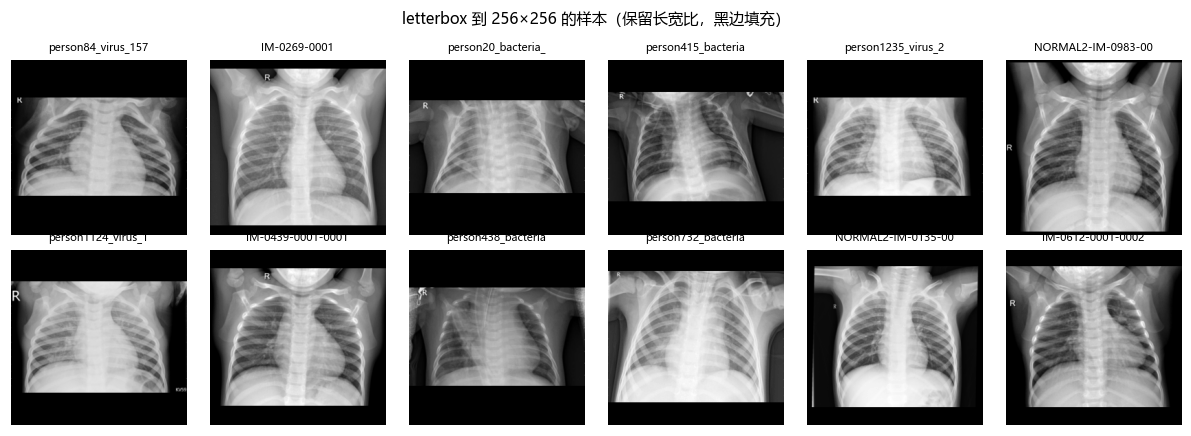

In [6]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def build_transforms(img_size: int, train: bool, aug: str = "full"):
    """缓存里已经是 256×256 的 letterbox 图，这里只做增强 + 缩放 + 归一化。"""
    if train and aug == "full":
        ops = [
            T.RandomResizedCrop(img_size, scale=(0.85, 1.0), ratio=(0.9, 1.11)),
            T.RandomAffine(degrees=7, translate=(0.05, 0.05)),
            T.RandomHorizontalFlip(p=0.5),
            T.ColorJitter(brightness=0.15, contrast=0.15),
        ]
    elif train and aug == "light":
        ops = [T.Resize(img_size), T.RandomHorizontalFlip(p=0.5)]
    else:
        ops = [T.Resize(img_size)]
    return T.Compose(ops + [T.Grayscale(num_output_channels=3), T.ToTensor(),
                            T.Normalize(MEAN, STD)])


class ChestXRay(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.df = df.reset_index(drop=True)
        self.rows = self.df["relpath"].map(ROW).to_numpy()
        self.labels = self.df["label"].to_numpy(dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = Image.fromarray(np.asarray(cache_arr[self.rows[i]]))
        return self.transform(img), int(self.labels[i]), i


# 看一眼 letterbox 后的样子
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, rel in zip(axes.ravel(), np.random.default_rng(0).choice(index.relpath, 12, replace=False)):
    with Image.open(DATA / rel) as im:
        ax.imshow(letterbox(im, CACHE_SIZE), cmap="gray")
    ax.set_title(Path(rel).stem[:18], fontsize=7)
    ax.axis("off")
fig.suptitle("letterbox 到 256×256 的样本（保留长宽比，黑边填充）", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "fig_samples.png")
plt.show()

## 3. 两个模型方案

- **方案 A（自建）**：4 个 conv block（Conv-BN-ReLU ×2 + MaxPool），通道 32→64→128→256，
  全局平均池化 + Dropout + 全连接，约 **1.17M** 参数，**从零训练**，输入 128×128。
- **方案 B（迁移）**：ImageNet 预训练 ResNet18（约 **11.2M** 参数），
  先冻结 backbone 只训分类头 3 轮，再全网络小学习率微调，输入 224×224。

In [7]:
class SmallCNN(nn.Module):
    def __init__(self, in_ch=3, num_classes=2, width=(32, 64, 128, 256), p_drop=0.3):
        super().__init__()

        def block(ci, co):
            return nn.Sequential(
                nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))

        layers, ci = [], in_ch
        for co in width:
            layers.append(block(ci, co))
            ci = co
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(p_drop), nn.Linear(ci, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_model(scheme: str, pretrained: bool = True) -> nn.Module:
    if scheme == "smallcnn":
        return SmallCNN()
    import timm
    os.environ.setdefault("HF_ENDPOINT", "https://hf-mirror.com")
    # 首次加载预训练权重时 huggingface_hub 会往 stderr 打一句"未认证请求"的提示，
    # 不影响运行但会让 notebook 看起来有告警，这里只在建模期间把它吞掉。
    with contextlib.redirect_stderr(io.StringIO()):
        return timm.create_model("resnet18", pretrained=pretrained, num_classes=2)


def set_frozen(model, scheme, frozen):
    if scheme == "smallcnn":
        return
    for name, p in model.named_parameters():
        if not name.startswith("fc."):
            p.requires_grad = not frozen


def count_params(m):
    return {"总参数": sum(p.numel() for p in m.parameters()),
            "可训练": sum(p.numel() for p in m.parameters() if p.requires_grad)}

In [8]:
cfg_tbl = []
for s, img in [("smallcnn", IMG_A), ("resnet18", IMG_B)]:
    # 只数参数，不需要下载预训练权重（也避免第一格就联网）
    m = build_model(s, pretrained=False)
    c = count_params(m)
    cfg_tbl.append({"方案": "A 自建 SmallCNN" if s == "smallcnn" else "B ResNet18 迁移",
                    "输入": f"{img}×{img}", "参数总量": f"{c['总参数'] / 1e6:.2f}M",
                    "是否预训练": "否" if s == "smallcnn" else "ImageNet"})
    del m
pd.DataFrame(cfg_tbl)

,方案,输入,参数总量,是否预训练
0,A 自建 SmallCNN,128×128,1.17M,否
1,B ResNet18 迁移,224×224,11.18M,ImageNet


## 4. 训练

统一流程：AdamW（分类头 1e-3 / backbone 1e-4）、余弦退火、按验证集 AUC 早停。
每折把验证集逐样本的预测概率保存成 csv，后面的 ROC、混淆矩阵、亚组分析全部基于它。

In [9]:
def evaluate(model, loader):
    model.eval()
    probs, ys, idxs = [], [], []
    with torch.no_grad():
        for x, y, i in loader:
            p = torch.softmax(model(x.to(DEVICE)), dim=1)[:, 1]
            probs.append(p.cpu().numpy())
            ys.append(y.numpy())
            idxs.append(i.numpy())
    return np.concatenate(ys), np.concatenate(probs), np.concatenate(idxs)


def compute_metrics(y_true, y_prob, thr=0.5):
    y_hat = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()
    return {"n": int(len(y_true)),
            "accuracy": float(accuracy_score(y_true, y_hat)),
            "sensitivity": float(recall_score(y_true, y_hat, zero_division=0)),
            "specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
            "precision": float(precision_score(y_true, y_hat, zero_division=0)),
            "f1": float(f1_score(y_true, y_hat, zero_division=0)),
            "auc": float(roc_auc_score(y_true, y_prob)),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def train_one(scheme, tr_df, va_df, te_df, tag, img_size, epochs,
              freeze_epochs=3, aug="full", class_weight="none", select="val",
              lr=1e-3, backbone_lr=1e-4, batch=32, patience=5, force=False):
    """训练一个模型；若 runs/<tag>/metrics.json 已存在且 force=False，直接读结果。"""
    out = RUNS / tag
    out.mkdir(parents=True, exist_ok=True)
    if (out / "metrics.json").exists() and not force:
        with open(out / "metrics.json", encoding="utf-8") as f:
            res = json.load(f)
        print(f"[{tag}] 已存在，读取缓存结果（best val AUC {res['best']['auc']:.4f}）")
        return res

    dl_tr = DataLoader(ChestXRay(tr_df, build_transforms(img_size, True, aug)),
                       batch_size=batch, shuffle=True, num_workers=NUM_WORKERS)
    dl_va = DataLoader(ChestXRay(va_df, build_transforms(img_size, False)),
                       batch_size=batch, shuffle=False, num_workers=NUM_WORKERS)

    model = build_model(scheme).to(DEVICE)
    frozen = scheme == "resnet18" and freeze_epochs > 0
    set_frozen(model, scheme, frozen)

    if class_weight == "balanced":
        cnt = np.bincount(tr_df.label.to_numpy(), minlength=2).astype(float)
        w = torch.tensor(cnt.sum() / (2 * cnt), dtype=torch.float32, device=DEVICE)
    else:
        w = None
    criterion = nn.CrossEntropyLoss(weight=w)

    head_names = ("fc.", "head.")
    opt = torch.optim.AdamW([
        {"params": [p for n, p in model.named_parameters() if n.startswith(head_names)], "lr": lr},
        {"params": [p for n, p in model.named_parameters() if not n.startswith(head_names)],
         "lr": backbone_lr}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    best, bad, hist = {"auc": -1.0, "epoch": -1}, 0, []
    t_start = time.time()
    for ep in range(1, epochs + 1):
        if frozen and ep == freeze_epochs + 1:
            set_frozen(model, scheme, False)
            frozen = False

        model.train()
        tot, nb, t0 = 0.0, 0, time.time()
        for x, y, _ in dl_tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            opt.step()
            tot += loss.item() * len(y)
            nb += len(y)
        sched.step()

        yv, pv, _ = evaluate(model, dl_va)
        m = compute_metrics(yv, pv)
        hist.append({"epoch": ep, "train_loss": tot / nb, **{f"val_{k}": v for k, v in m.items()}})
        if select == "last":
            # 全量重训时不在训练集内部挑 epoch，固定轮数直接取最后一轮
            best = {"auc": m["auc"], "epoch": ep}
            torch.save(model.state_dict(), out / "best.pt")
        elif m["auc"] > best["auc"]:
            best = {"auc": m["auc"], "epoch": ep}
            torch.save(model.state_dict(), out / "best.pt")
            bad = 0
        else:
            bad += 1
        print(f"[{tag}] ep{ep:02d} loss {tot / nb:.4f} | val AUC {m['auc']:.4f} "
              f"acc {m['accuracy']:.4f} sen {m['sensitivity']:.4f} spe {m['specificity']:.4f} "
              f"| {time.time() - t0:.0f}s")
        if bad >= patience:
            print(f"[{tag}] early stop @ ep{ep}")
            break

    model.load_state_dict(torch.load(out / "best.pt", map_location=DEVICE, weights_only=True))
    yv, pv, iv = evaluate(model, dl_va)
    res = {"tag": tag, "scheme": scheme, "img_size": img_size, "epochs": epochs,
           "params": count_params(model), "history": hist, "best": best,
           "val_metrics": compute_metrics(yv, pv), "train_seconds": time.time() - t_start}
    pd.DataFrame({"relpath": va_df.reset_index(drop=True).loc[iv, "relpath"].values,
                  "patient": va_df.reset_index(drop=True).loc[iv, "patient"].values,
                  "subtype": va_df.reset_index(drop=True).loc[iv, "subtype"].values,
                  "y_true": yv, "y_prob": pv}).to_csv(out / "preds_val.csv", index=False)

    if te_df is not None:
        dl_te = DataLoader(ChestXRay(te_df, build_transforms(img_size, False)),
                           batch_size=batch, shuffle=False, num_workers=NUM_WORKERS)
        yt, pt, it = evaluate(model, dl_te)
        res["test_metrics"] = compute_metrics(yt, pt)
        pd.DataFrame({"relpath": te_df.reset_index(drop=True).loc[it, "relpath"].values,
                      "patient": te_df.reset_index(drop=True).loc[it, "patient"].values,
                      "subtype": te_df.reset_index(drop=True).loc[it, "subtype"].values,
                      "y_true": yt, "y_prob": pt}).to_csv(out / "preds_test.csv", index=False)

    with open(out / "metrics.json", "w", encoding="utf-8") as f:
        json.dump(res, f, ensure_ascii=False, indent=2)
    return res

### 5 折交叉验证（两个方案）

In [10]:
fold_results = {"A": [], "B": []}

for scheme, img_size, epochs, key in [("smallcnn", IMG_A, EPOCHS_A, "A"),
                                      ("resnet18", IMG_B, EPOCHS_B, "B")]:
    for k in FOLDS:
        tr = train_all[train_all.fold != k]
        va = train_all[train_all.fold == k]
        res = train_one(scheme, tr, va, None, tag=f"{key}_fold{k}",
                        img_size=img_size, epochs=epochs, force=RUN_TRAINING)
        fold_results[key].append(res)

print("\n5 折完成")

[A_fold0] 已存在，读取缓存结果（best val AUC 0.9970）
[A_fold1] 已存在，读取缓存结果（best val AUC 0.9987）
[A_fold2] 已存在，读取缓存结果（best val AUC 0.9981）
[A_fold3] 已存在，读取缓存结果（best val AUC 0.9982）
[A_fold4] 已存在，读取缓存结果（best val AUC 0.9986）
[B_fold0] 已存在，读取缓存结果（best val AUC 0.9956）
[B_fold1] 已存在，读取缓存结果（best val AUC 0.9976）
[B_fold2] 已存在，读取缓存结果（best val AUC 0.9972）
[B_fold3] 已存在，读取缓存结果（best val AUC 0.9983）
[B_fold4] 已存在，读取缓存结果（best val AUC 0.9971）

5 折完成


In [11]:
rows = []
for key, name in [("A", "A 自建 SmallCNN"), ("B", "B ResNet18 迁移")]:
    for r in fold_results[key]:
        rows.append({"方案": name, "折": r["tag"].split("fold")[-1],
                     **{k: v for k, v in r["val_metrics"].items() if k != "n"}})
fold_df = pd.DataFrame(rows)

cols = ["auc", "accuracy", "sensitivity", "specificity", "f1"]
mean_df = fold_df.groupby("方案")[cols].mean()
std_df = fold_df.groupby("方案")[cols].agg(lambda s: s.std(ddof=0))
print("\n5 折验证集结果（均值 ± 标准差）：")
for name in mean_df.index:
    m_, s_ = mean_df.loc[name], std_df.loc[name]
    print(f"  {name}: AUC {m_['auc']:.4f}±{s_['auc']:.4f} | "
          f"Acc {m_['accuracy']:.4f}±{s_['accuracy']:.4f} | "
          f"Sen {m_['sensitivity']:.4f}±{s_['sensitivity']:.4f} | "
          f"Spe {m_['specificity']:.4f}±{s_['specificity']:.4f}")
fold_df.round(4)


5 折验证集结果（均值 ± 标准差）：
  A 自建 SmallCNN: AUC 0.9981±0.0006 | Acc 0.9792±0.0037 | Sen 0.9924±0.0040 | Spe 0.9405±0.0258
  B ResNet18 迁移: AUC 0.9972±0.0009 | Acc 0.9780±0.0037 | Sen 0.9842±0.0053 | Spe 0.9599±0.0121


,方案,折,accuracy,sensitivity,specificity,precision,f1,auc,tn,fp,fn,tp
0,A 自建 SmallCNN,0,0.9735,0.9976,0.9015,0.9681,0.9826,0.9970,247,27,2,820
1,A 自建 SmallCNN,1,0.9836,0.9922,0.9580,0.9858,0.9890,0.9987,251,11,6,766
2,A 自建 SmallCNN,2,0.9764,0.9937,0.9231,0.9754,0.9845,0.9981,240,20,5,794
3,A 自建 SmallCNN,3,0.9799,0.9931,0.9453,0.9795,0.9862,0.9982,259,15,5,715
4,A 自建 SmallCNN,4,0.9824,0.9852,0.9748,0.9906,0.9879,0.9986,271,7,11,734
5,B ResNet18 迁移,0,0.9772,0.9903,0.9380,0.9795,0.9849,0.9956,257,17,8,814
6,B ResNet18 迁移,1,0.9778,0.9832,0.9618,0.9870,0.9851,0.9976,252,10,13,759
7,B ResNet18 迁移,2,0.9745,0.9800,0.9577,0.9861,0.9831,0.9972,249,11,16,783
8,B ResNet18 迁移,3,0.9849,0.9903,0.9708,0.9889,0.9896,0.9983,266,8,7,713
9,B ResNet18 迁移,4,0.9756,0.9772,0.9712,0.9891,0.9831,0.9971,270,8,17,728


## 5. 评估

注意：训练集里 74.1% 是肺炎，**"全部判为肺炎"就能拿到 0.741 的准确率**，
所以下面同时看 AUC、灵敏度、特异度，不能只看准确率。

In [12]:
def pooled_preds(key):
    """把 5 折验证集预测拼起来，得到一张 ROC。"""
    dfs = [pd.read_csv(RUNS / f"{key}_fold{k}" / "preds_val.csv") for k in FOLDS]
    return pd.concat(dfs, ignore_index=True)


preds = {k: pooled_preds(k) for k in ["A", "B"]}
for k, d in preds.items():
    m = compute_metrics(d.y_true.values, d.y_prob.values)
    print(f"{k}: n={m['n']} AUC={m['auc']:.4f} Acc={m['accuracy']:.4f} "
          f"Sen={m['sensitivity']:.4f} Spe={m['specificity']:.4f} F1={m['f1']:.4f}")

A: n=5206 AUC=0.9978 Acc=0.9791 Sen=0.9925 Spe=0.9407 F1=0.9860
B: n=5206 AUC=0.9971 Acc=0.9779 Sen=0.9842 Spe=0.9599 F1=0.9851


### ROC 曲线（5 折验证集合并）

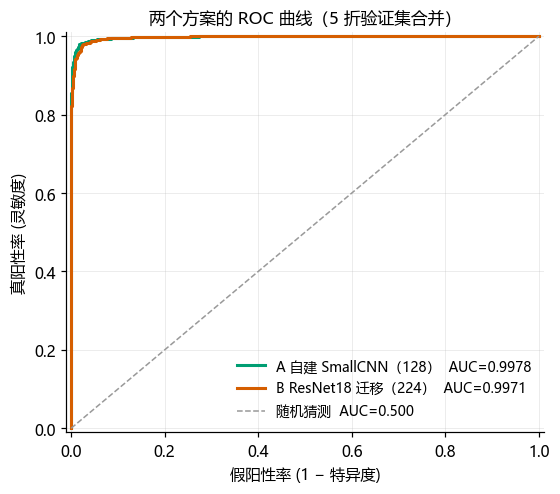

In [13]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for (k, label), color, ls in [(("A", "A 自建 SmallCNN（128）"), C_THIRD, "-"),
                              (("B", "B ResNet18 迁移（224）"), C_PNEU, "-")]:
    d = preds[k]
    fpr, tpr, _ = roc_curve(d.y_true, d.y_prob)
    ax.plot(fpr, tpr, color=color, lw=2, ls=ls,
            label=f"{label}  AUC={roc_auc_score(d.y_true, d.y_prob):.4f}")
ax.plot([0, 1], [0, 1], color="#999999", lw=1, ls="--", label="随机猜测  AUC=0.500")
ax.set_xlabel("假阳性率 (1 − 特异度)")
ax.set_ylabel("真阳性率 (灵敏度)")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("两个方案的 ROC 曲线（5 折验证集合并）")
plt.tight_layout()
plt.savefig(FIG / "fig_roc.png")
plt.show()

### 阈值选择（Youden 指数）

阈值 0.5 只在两类先验接近时合理。本数据训练集里约 74% 是肺炎、官方测试集约 63%，
跨队列时固定用 0.5 会把大批正常片判成肺炎（后面测试集上特异度会明显塌陷）。
这里在验证集上按 Youden 指数 J = 灵敏度 + 特异度 − 1 选阈值，再**原样**用到测试集上。

In [14]:
def youden_threshold(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    return float(thr[np.argmax(tpr - fpr)])


THR = {}
for k in ["A", "B"]:
    y_, p_ = preds[k].y_true.values, preds[k].y_prob.values
    THR[k] = youden_threshold(y_, p_)
    m05, mt = compute_metrics(y_, p_, 0.5), compute_metrics(y_, p_, THR[k])
    print(f"{k}: Youden 阈值 {THR[k]:.3f} | "
          f"验证集 Acc {m05['accuracy']:.4f}→{mt['accuracy']:.4f} "
          f"Sen {m05['sensitivity']:.4f}→{mt['sensitivity']:.4f} "
          f"Spe {m05['specificity']:.4f}→{mt['specificity']:.4f}")

A: Youden 阈值 0.860 | 验证集 Acc 0.9791→0.9800 Sen 0.9925→0.9793 Spe 0.9407→0.9822
B: Youden 阈值 0.627 | 验证集 Acc 0.9779→0.9779 Sen 0.9842→0.9782 Spe 0.9599→0.9770


### 混淆矩阵（阈值 0.5）

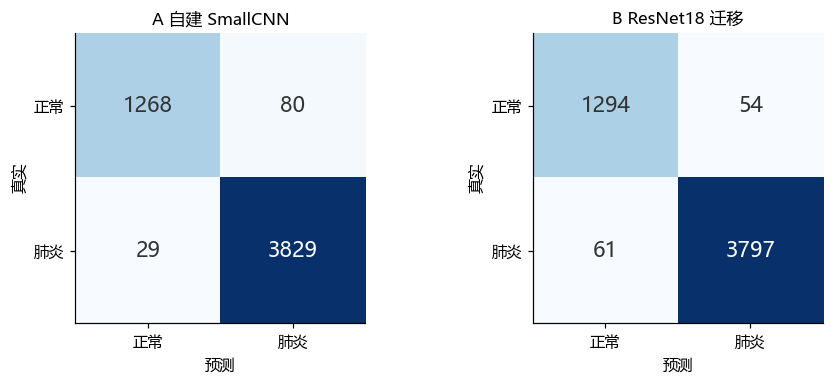

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6))
for ax, (k, name) in zip(axes, [("A", "A 自建 SmallCNN"), ("B", "B ResNet18 迁移")]):
    d = preds[k]
    cm = confusion_matrix(d.y_true, (d.y_prob >= 0.5).astype(int), labels=[0, 1])
    im = ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() * 0.55 else "#333333")
    ax.set_xticks([0, 1], ["正常", "肺炎"])
    ax.set_yticks([0, 1], ["正常", "肺炎"])
    ax.set_xlabel("预测")
    ax.set_ylabel("真实")
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.savefig(FIG / "fig_confusion.png")
plt.show()

### 全量训练集重训 + 官方测试集

5 折的作用是确定模型和训练轮数；确定之后用全部训练数据重训一遍，
**测试集只在最后评估一次，全程不参与任何模型或 epoch 的选择**。
轮数取 5 折里最优轮数的中位数。

In [16]:
if RUN_FINAL:
    final = {}
    for scheme, img_size, epochs, key in [("smallcnn", IMG_A, EPOCHS_A, "A"),
                                          ("resnet18", IMG_B, EPOCHS_B, "B")]:
        best_eps = int(np.median([r["best"]["epoch"] for r in fold_results[key]]))
        print(f"[{key}] 全量重训 {best_eps} 轮")
        final[key] = train_one(scheme, train_all, train_all[train_all.fold == 0], test_df,
                               tag=f"{key}_test", img_size=img_size, epochs=best_eps,
                               select="last", force=True)
    print("已完成全量训练 + 测试集评估")
else:
    print("RUN_FINAL=False，跳过全量训练；测试集结果读取已有 runs/*_test")

RUN_FINAL=False，跳过全量训练；测试集结果读取已有 runs/*_test


### 测试集结果与亚组分析

肺炎文件里带有 `bacteria` / `virus` 亚型标记。分别把「正常 vs 细菌性」和
「正常 vs 病毒性」拆开算 AUC，可以看出模型是不是只会认其中一类。

In [17]:
test_runs = {}
for k in ["A", "B"]:
    p = RUNS / f"{k}_test" / "preds_test.csv"
    if p.exists():
        test_runs[k] = pd.read_csv(p)

if test_runs:
    for k, d in test_runs.items():
        y_, p_ = d.y_true.values, d.y_prob.values
        m05 = compute_metrics(y_, p_, 0.5)
        mt = compute_metrics(y_, p_, THR[k])
        print(f"[测试集 {k}] AUC={mt['auc']:.4f} | 阈值0.50: Acc={m05['accuracy']:.4f} "
              f"Sen={m05['sensitivity']:.4f} Spe={m05['specificity']:.4f} | "
              f"阈值{THR[k]:.2f}: Acc={mt['accuracy']:.4f} "
              f"Sen={mt['sensitivity']:.4f} Spe={mt['specificity']:.4f}")

    rows = []
    for k, d in test_runs.items():
        for sub in ["bacteria", "virus"]:
            dd = d[(d.y_true == 0) | (d.subtype == sub)]
            rows.append({"方案": k, "亚组": f"正常 vs {sub}",
                         "n": len(dd),
                         "AUC": roc_auc_score(dd.y_true, dd.y_prob),
                         "灵敏度": recall_score(dd.y_true, (dd.y_prob >= .5).astype(int))})
    print("\n亚组分析：")
    print(pd.DataFrame(rows).round(4).to_string(index=False))
else:
    print("尚未生成测试集预测：把 RUN_FINAL 设为 True 并运行上面的单元。")

[测试集 A] AUC=0.9297 | 阈值0.50: Acc=0.7913 Sen=0.9922 Spe=0.4545 | 阈值0.86: Acc=0.8463 Sen=0.9845 Spe=0.6147
[测试集 B] AUC=0.9655 | 阈值0.50: Acc=0.8689 Sen=0.9922 Spe=0.6623 | 阈值0.63: Acc=0.8883 Sen=0.9845 Spe=0.7273

亚组分析：
方案             亚组   n    AUC    灵敏度
 A 正常 vs bacteria 471 0.9400 0.9917
 A    正常 vs virus 378 0.9130 0.9932
 B 正常 vs bacteria 471 0.9725 0.9917
 B    正常 vs virus 378 0.9540 0.9932


## 6. 中间特征与可解释性

题目要求分析中间特征，这里两条都做：
- **t-SNE**：把倒数第二层的特征降到二维，看两类样本是否天然分开；
- **Grad-CAM**：看模型做判断时盯着图像哪个区域。

In [18]:
def load_trained(key):
    scheme = "smallcnn" if key == "A" else "resnet18"
    img_size = IMG_A if key == "A" else IMG_B
    # 这里建完马上就会 load_state_dict 覆盖全部权重，预训练值用不上，
    # 用 pretrained=False 既不联网也不会触发下载提示。
    model = build_model(scheme, pretrained=False).to(DEVICE)
    model.load_state_dict(torch.load(RUNS / f"{key}_fold0" / "best.pt",
                                     map_location=DEVICE, weights_only=True))
    model.eval()
    return model, scheme, img_size


def features_of(model, scheme, x):
    """倒数第二层特征：卷积图做全局平均池化后展平。

    注意 timm 的 forward_features 返回的是 (B, 512, 7, 7) 的特征图（不含池化），
    必须自己池化，否则拿到的是一万多维的展平特征。
    """
    f = model.forward_features(x) if scheme == "resnet18" else model.features(x)
    if f.ndim > 2:
        f = F.adaptive_avg_pool2d(f, 1)
    return f.flatten(1)

### t-SNE（倒数第二层特征，测试集）

特征维度: (618, 512)


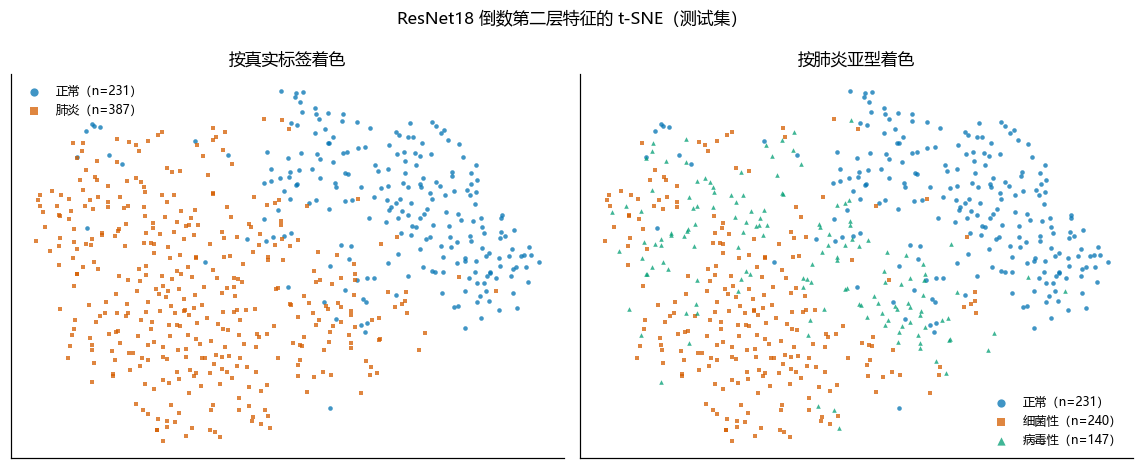

In [19]:
model_b, scheme_b, img_b = load_trained("B")
dl_te_b = DataLoader(ChestXRay(test_df, build_transforms(img_b, False)),
                     batch_size=64, shuffle=False, num_workers=0)

feats, ys, subs = [], [], []
with torch.no_grad():
    for x, y, _ in dl_te_b:
        feats.append(features_of(model_b, scheme_b, x.to(DEVICE)).cpu().numpy())
        ys.append(y.numpy())
X = np.concatenate(feats)
y = np.concatenate(ys)
subs = test_df.reset_index(drop=True)["subtype"].values
print("特征维度:", X.shape)

ts = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED,
          learning_rate="auto", n_jobs=1)   # n_jobs=1：Windows 下 joblib 探测核心数会报 warning
Z = ts.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
for ax, (title, groups, colors) in zip(axes, [
        ("按真实标签着色", ["正常", "肺炎"], [C_NORMAL, C_PNEU]),
        ("按肺炎亚型着色", ["正常", "细菌性", "病毒性"], [C_NORMAL, C_PNEU, C_THIRD])]):
    masks = {"正常": y == 0, "肺炎": y == 1, "细菌性": subs == "bacteria", "病毒性": subs == "virus"}
    markers = ["o", "s", "^"]
    for i, (g, c) in enumerate(zip(groups, colors)):
        m = masks[g]
        ax.scatter(Z[m, 0], Z[m, 1], s=9, c=c, marker=markers[i], alpha=0.75,
                   linewidths=0, label=f"{g}（n={m.sum()}）")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.legend(fontsize=8, markerscale=1.8)
fig.suptitle("ResNet18 倒数第二层特征的 t-SNE（测试集）", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig_tsne.png")
plt.show()

### Grad-CAM

In [20]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._fwd)
        layer.register_full_backward_hook(self._bwd)

    def _fwd(self, m, i, o):
        self.acts = o.detach()

    def _bwd(self, m, gi, go):
        self.grads = go[0].detach()

    def __call__(self, x, cls=1):
        self.model.zero_grad()
        out = self.model(x)
        out[0, cls].backward()
        w = self.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0]
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


cam = GradCAM(model_b, model_b.layer4[-1])

Grad-CAM 样本： ['正确识别肺炎', '漏诊的肺炎', '正确识别正常', '误判为肺炎的正常']


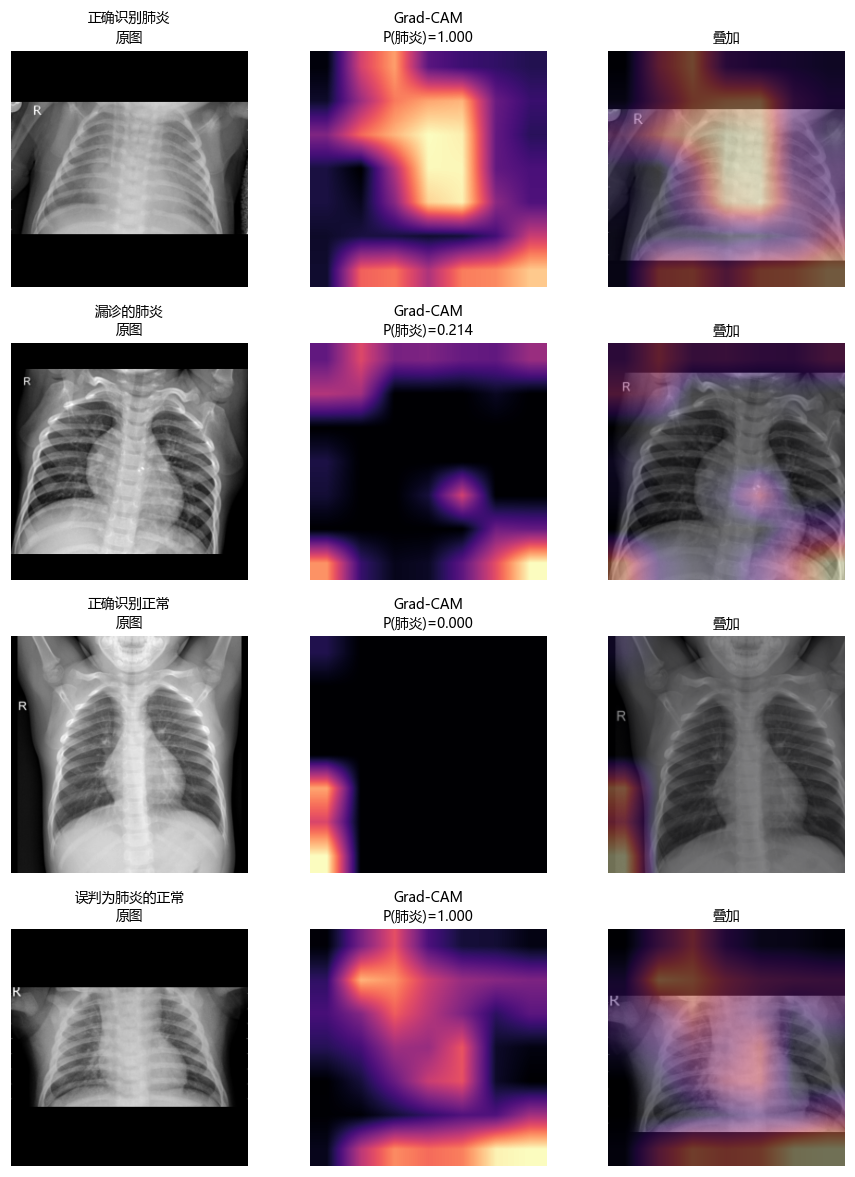

In [21]:
def cam_for(relpath, img_size):
    with Image.open(DATA / relpath) as im:
        lb = letterbox(im, CACHE_SIZE)
        raw = np.asarray(lb)
    x = build_transforms(img_size, False)(lb).unsqueeze(0).to(DEVICE)
    prob = torch.softmax(model_b(x), 1)[0, 1].item()
    heat = cam(x, cls=1).detach().cpu().numpy()
    return raw, heat, prob


d_test = pd.read_csv(RUNS / "B_test" / "preds_test.csv") if (RUNS / "B_test" / "preds_test.csv").exists() \
    else pd.read_csv(RUNS / "B_fold0" / "preds_val.csv")
d_test = d_test.copy()
d_test["pred"] = (d_test.y_prob >= 0.5).astype(int)

def pick(mask, ascending):
    sub = d_test[mask].sort_values("y_prob", ascending=ascending)
    return sub.iloc[0] if len(sub) else None


cases = [(n, r) for n, r in [
    ("正确识别肺炎", pick((d_test.y_true == 1) & (d_test.pred == 1), False)),
    ("漏诊的肺炎", pick((d_test.y_true == 1) & (d_test.pred == 0), True)),
    ("正确识别正常", pick((d_test.y_true == 0) & (d_test.pred == 0), True)),
    ("误判为肺炎的正常", pick((d_test.y_true == 0) & (d_test.pred == 1), False)),
] if r is not None]
print("Grad-CAM 样本：", [n for n, _ in cases])

fig, axes = plt.subplots(len(cases), 3, figsize=(8.4, 2.7 * len(cases)))
for row, (name, r) in zip(np.atleast_2d(axes), cases):
    raw, heat, prob = cam_for(r.relpath, img_b)
    row[0].imshow(raw, cmap="gray")
    row[0].set_title(f"{name}\n原图", fontsize=9)
    row[1].imshow(heat, cmap="magma")
    row[1].set_title(f"Grad-CAM\nP(肺炎)={prob:.3f}", fontsize=9)
    row[2].imshow(raw, cmap="gray")
    row[2].imshow(heat, cmap="magma", alpha=0.45)
    row[2].set_title("叠加", fontsize=9)
    for a in row:
        a.axis("off")
plt.tight_layout()
plt.savefig(FIG / "fig_gradcam.png")
plt.show()

## 7. 题目要求的 70 / 30 敏感性分析

In [22]:
pool_results = {}
for scheme, img_size, epochs, key in [("smallcnn", IMG_A, EPOCHS_A, "A"),
                                      ("resnet18", IMG_B, EPOCHS_B, "B")]:
    p_tr, p_va = train_test_split(pool_tr.index, test_size=0.1, random_state=SEED,
                                  stratify=pool_tr["label"])
    pool_results[key] = train_one(scheme, pool_tr.loc[p_tr], pool_tr.loc[p_va], pool_te,
                                  tag=f"{key}_pool70", img_size=img_size,
                                  epochs=epochs, force=RUN_TRAINING)

for k, r in pool_results.items():
    m = r.get("test_metrics")
    if m:
        print(f"[70/30] {k}: AUC={m['auc']:.4f} Acc={m['accuracy']:.4f} "
              f"Sen={m['sensitivity']:.4f} Spe={m['specificity']:.4f}")

[A_pool70] 已存在，读取缓存结果（best val AUC 0.9945）
[B_pool70] 已存在，读取缓存结果（best val AUC 0.9952）
[70/30] A: AUC=0.9945 Acc=0.9686 Sen=0.9748 Spe=0.9520
[70/30] B: AUC=0.9945 Acc=0.9669 Sen=0.9717 Spe=0.9541


## 8. 汇总导出

图中已保存到 `figures/`，可直接插入报告。

In [23]:
summary = []
for key, name in [("A", "A 自建 SmallCNN"), ("B", "B ResNet18 迁移")]:
    keep = ("n", "auc", "accuracy", "sensitivity", "specificity", "precision", "f1")
    d = preds[key]
    m = compute_metrics(d.y_true.values, d.y_prob.values, THR[key])
    summary.append({"方案": name, "评估集": "5折验证集(合并)", "阈值": round(THR[key], 3),
                    **{k: round(v, 4) for k, v in m.items() if k in keep}})
    if key in test_runs:
        mt = compute_metrics(test_runs[key].y_true.values, test_runs[key].y_prob.values, THR[key])
        summary.append({"方案": name, "评估集": "官方测试集", "阈值": round(THR[key], 3),
                        **{k: round(v, 4) for k, v in mt.items() if k in keep}})
summary_df = pd.DataFrame(summary)
summary_df.to_csv(RUNS / "summary.csv", index=False, encoding="utf-8")
print(summary_df.to_string(index=False))
print("\n图已保存到:", FIG)
print(sorted(p.name for p in FIG.glob("*.png")))

           方案       评估集    阈值    n  accuracy  sensitivity  specificity  precision     f1    auc
A 自建 SmallCNN 5折验证集(合并) 0.860 5206    0.9800       0.9793       0.9822     0.9937 0.9864 0.9978
A 自建 SmallCNN     官方测试集 0.860  618    0.8463       0.9845       0.6147     0.8106 0.8891 0.9297
B ResNet18 迁移 5折验证集(合并) 0.627 5206    0.9779       0.9782       0.9770     0.9919 0.9850 0.9971
B ResNet18 迁移     官方测试集 0.627  618    0.8883       0.9845       0.7273     0.8581 0.9170 0.9655

图已保存到: C:\Users\35736\Desktop\人工智能与概率建模\小组期末作业\figures
['fig_confusion.png', 'fig_gradcam.png', 'fig_roc.png', 'fig_samples.png', 'fig_tsne.png']
